# Problem 1: Calculating $\pi$ using Monte Carlo Methods
---------------------------------------------

# Background 

`Pi` is in fact what mathematicians call an irrational number, meaning that it is a number that can't be written as a simple fraction, or in other words it has an infinite, non-repeating number of decimal digits. Move over 3.14 - here is the value of `Pi` to 100 digits:
 
```
3.1415926535897932384626433832795028841971693993751058209749445923078164062862089986280348253421170679
```
 
If you think that's too much to retain, in October 2015 Suresh Kumar Sharma of India recited 70,030 digits of `Pi` in just over 17 hours.
 
The fact that `Pi` is infinite hasn't stopped mathematicians trying to calculate it to as many digits as possible.  In November 2016, Peter Trueb used some fairly chunky computing power to calculate it to 22,459,157,718,361 decimal places.

In this problem, we will approximate `Pi` by throwing darts at a dart board using Monte Carlo simulation [Monte Carlo simulation](https://www.ibm.com/cloud/learn/monte-carlo-simulation). Monte Carlo methods employ statistical algorithms to estimate an unknown quantity. For us, this unknown quantity is . The method starts by inscribing a circle inside of a square.


Write a program to create the square and circle and randomly create points that fall within the square. Count the number of points that fall within the circle. Finally, compute the ratio of the number of points in the circle to the total number of points.

<img src="assets/darts.png" width="50%">

_Figure 1. The circle and the square give us our dartboard and back-board respectively, with the circle fitting perfectly inside the square with a radius of 1._


## Methodology

The definition of a circle is a point, called the center, and all the points that are equal distance from the center. Given the center of the circle, use the distance function to test if a random point is inside the circle; that is, the distance from the point to the circle's center is less than the circle’s radius.

- Area of a square: $s_{area} = (2 r)^2$
- Area of the circle: $c_{area} = \pi r^2$
- $c_{area}/s_{area} = (\pi r^2) / (4 r^2) = \pi / 4$
- $\pi = 4 * c/s$

In [9]:
# Importing modules that we will need
import random
import numpy as np
import matplotlib.pyplot as plt
import time as t

In [10]:
# Generate random `x,y` coordinates (ie. the dart throws) and count the number of hits

def estimate_pi(num_points):
    start_time = t.perf_counter()
    rng = np.random.default_rng()
    points= rng.uniform(-1,1,size=(num_points,2))
    hits = 0

    inside_point=[]
    outside_point=[]

    for x,y in points:
        if x**2+y**2 <=1:
            hits+=1
            inside_point.append((x,y))
        else:
            outside_point.append((x,y))

    # Computing pi from the simulation data and calculating the estimate
    pi_estimate = 4 * hits / num_points
    end_time = t.perf_counter()
    time = end_time - start_time
    print("Time taken for the simulation: ", time)
    print(f"Estimated value of π: {pi_estimate}")
    return time, inside_point, outside_point

In [11]:
# Initializing the number of samples in Monte Carlo simulation (ie. dart throws)
num_points = [1,10,100,1000,10000,100000,1000000,10000000]
time_taken=[]
inside_points=np.array([])
outside_points=np.array([])
for n in num_points:
    time, in_points, out_points = estimate_pi(n)
    time_taken.append(time)
    if n==1000:
        inside_points = np.array(in_points)
        outside_points = np.array(out_points)

# Table showing the number of samples and the time taken for each simulation
print("\nNumber of Samples\tTime Taken (seconds)")
for n, t in zip(num_points, time_taken):
    print(f"{n}\t\t\t{t:.4f}")

Time taken for the simulation:  0.005074332992080599
Estimated value of π: 4.0
Time taken for the simulation:  0.0002072919742204249
Estimated value of π: 3.2
Time taken for the simulation:  0.00010120798833668232
Estimated value of π: 3.24
Time taken for the simulation:  0.0005449170130304992
Estimated value of π: 3.18
Time taken for the simulation:  0.006606833019759506
Estimated value of π: 3.1812
Time taken for the simulation:  0.06190625001909211
Estimated value of π: 3.143
Time taken for the simulation:  0.5453752499888651
Estimated value of π: 3.143772
Time taken for the simulation:  5.584512332978193
Estimated value of π: 3.1413428

Number of Samples	Time Taken (seconds)
1			0.0051
10			0.0002
100			0.0001
1000			0.0005
10000			0.0066
100000			0.0619
1000000			0.5454
10000000			5.5845


In [12]:
print(len(inside_points))
print(len(outside_points))

795
205


<img src="assets/darts2.png" width="50%">

_Figure 2: Plot your dart throws using matplotlib simular to that shown in the figure._

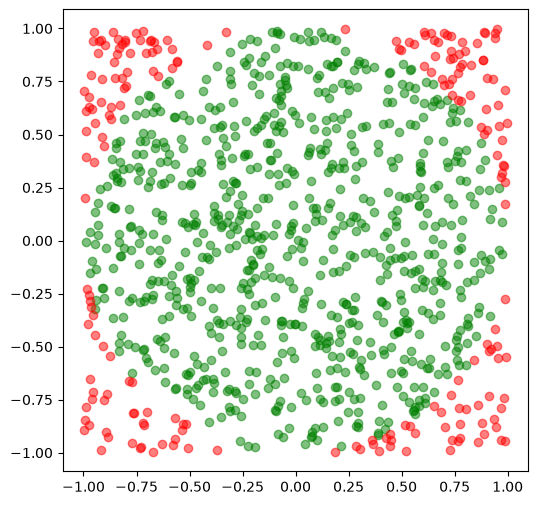

In [13]:
# Plot the points using matplotlib similar to Figure above
# Printing plot for n=1000

plt.figure(figsize=(6,6))
plt.scatter(inside_points[:,0], inside_points[:,1], color='green', label='Inside Circle', alpha=0.5)
plt.scatter(outside_points[:,0], outside_points[:,1], color='red', label='Outside Circle', alpha=0.5)
plt.axis('equal')
plt.show()  

# Results

Construct a table (using markdown) to benchmark a series of experiments for `n` number of points. Also, include the time, $t$, (in seconds) that the simulation took to complete. Choose point values that help to identify trends with the data.

_Only include the time needed to simulate the points and estimate $\pi$. Do not include the time to plot the data._

$n$ points | $t$ (seconds) | value of $\pi$
--- | -- |  :---: 
1 | -  | -
10 | -  | -
100 | -  | -
1000 | -  | -
10000 | -  | -
... | ... | ...

The table is present above with considering num_points = [1,10,100,1000,10000,100000,1000000,10000000] along with their estimates

# Analysis

Considering the numeric types used in this calculation, what is the actual accuracy of this calculation?

The randomly generated x and y coordinates are stored as float64 values. A float64 provides approximately 15–16 significant decimal digits of numerical precision. The calculated pi_estimate is also represented as a floating-point value.

However, the accuracy of the estimated value of \pi is primarily limited by the Monte Carlo sampling process rather than by floating-point precision. For N = 10{,}000{,}000 points, the simulation produced

$$
\hat{\pi} = 3.1408612
$$

The reference value of \pi can be obtained using np.pi:

$$
\pi \approx 3.141592653589793
$$

The actual absolute error of the estimate can therefore be calculated as

$$
\text{Absolute Error} = |\hat{\pi} - \pi|
$$

which gives

$$
|3.1408612 - 3.141592653589793|
\approx 0.00073145
$$

Thus, although float64 itself provides approximately 15–16 significant digits of precision, the Monte Carlo estimate is considerably less accurate because of statistical sampling error.


In [14]:
pi_estimate= 3.1408612 # n=10000000 case

absolute_error = abs(pi_estimate - np.pi)

relative_error = absolute_error / np.pi

percentage_error = relative_error * 100

print("Absolute error:", absolute_error)
print("Relative error:", relative_error)
print("Percentage error:", percentage_error*100)

Absolute error: 0.0007314535897933183
Relative error: 0.00023282890891583626
Percentage error: 2.3282890891583627


Given your implementation, approximate how long it would take to compute $\pi$ to 70,030 digits?

For a standard Monte Carlo simulation, the statistical error decreases approximately as

$$
\text{error} \propto \frac{1}{\sqrt{N}},
$$

where $N$ is the number of random samples. This is a standard theoretical convergence result for Monte Carlo methods.

To obtain approximately $d$ correct decimal digits, the error must be on the order of

$$
10^{-d}.
$$

Therefore,

$$
\frac{1}{\sqrt{N}} \approx 10^{-d}.
$$

For $d = 70{,}030$,

$$
N \approx 10^{2d}
= 10^{140060}.
$$

Thus, approximately $10^{140060}$ random points would be required.

My implementation processes each random point once, so its runtime grows approximately linearly with $N$. If $T_0$ is the measured runtime for $N_0 = 10^7$ points, the estimated runtime is

$$
T \approx T_0 \frac{10^{140060}}{10^7}
= T_0 \times 10^{140053} \text{ seconds}.
$$

Therefore, computing $\pi$ to 70,030 digits using this Monte Carlo implementation would require an astronomically large amount of time and is computationally infeasible.Also, a point to consider is, the current implementation uses float64, which provides only approximately 15–16 significant decimal digits of precision. Therefore, the numeric type used by the implementation would also be incapable of representing 70,030 digits of $\pi$.